# Confronto modelli — risultati di cross-validation

Notebook per confrontare i file `cv_summary_*.tsv` (uno per modello).
Funziona con **2 o più file**: basta aggiungerli alla lista `FILES` qui sotto (oppure lasciare il `glob`).

Grafici prodotti:
1. Tabella riassuntiva (micro + macro)
2. P / R / F1 complessivi con barre d'errore (std sui fold)
3. F1 micro per frame
4. F1 per etichetta (con supporto)
5. Heatmap F1 etichetta × modello
6. Δ F1 rispetto al modello di riferimento (con indicazione della variabilità)
7. Precision vs Recall per etichetta
8. F1 vs numero di esempi gold
9. Composizione degli errori (TP / FP / FN)
10. Radar per frame

## 0. Configurazione

In [179]:
import glob, re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# --- File da confrontare -----------------------------------------------------
# Opzione A: tutti i cv_summary_*.tsv in una cartella
# FILES = sorted(glob.glob("cv_summary_*.tsv"))
# Opzione B: lista esplicita
FILES = ["results_multiclass_mBERT.tsv",
        #  "results_multitask_MacBERTh_new.tsv",
        "results_multitask_MacBERTh.tsv",
         "results_multitask_mBERT.tsv",
         "results_multitask_BERT.tsv",
         "results_multiclass_MacBERTh.tsv",
         "results_multiclass_BERT.tsv",
         "lexical_baseline_results.tsv"
         ]

# Nomi leggibili (facoltativo). Chiave = nome ricavato dal file.
PRETTY_NAMES = {
    "multiclass_mBERT": "mBERT_class",
    "multitask_mBERT": "mBERT_task",
    "multiclass_MacBERTh": "MacBERTh_class",
    "multitask_MacBERTh": "MacBERTh_task",
   " multitask_EngBERT": "BERT_task"
}

# Modello di riferimento per i grafici Δ (None = il primo della lista)
BASELINE = "lexical_baseline_results.tsv"
# BASELINE = None

# Metrica principale: "mean" (media ± std sui fold) oppure "pooled" (TP/FP/FN sommati)
AGG = "mean"

SAVE_FIGS = True          # salva i grafici in PNG/PDF
OUT_DIR = Path("figures")
DPI = 150

assert len(FILES) >= 1, "Nessun file trovato: controlla FILES"
print("\n".join(FILES))

results_multiclass_mBERT.tsv
results_multitask_MacBERTh.tsv
results_multitask_mBERT.tsv
results_multitask_BERT.tsv
results_multiclass_MacBERTh.tsv
results_multiclass_BERT.tsv
lexical_baseline_results.tsv


In [180]:
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titleweight": "bold",
    "font.size": 10,
})
PALETTE = ["#1f77b4", "#d62728", "#2ca02c", "#9467bd", "#ff7f0e", "#8c564b", "#17becf", "#e377c2"]

# if SAVE_FIGS:
#     OUT_DIR.mkdir(exist_ok=True)

# def savefig(fig, name):
#     if SAVE_FIGS:
#         for ext in ("png", "pdf"):
#             fig.savefig(OUT_DIR / f"{name}.{ext}", dpi=DPI, bbox_inches="tight")

## 1. Caricamento dati

In [181]:
def model_name(path):
    stem = Path(path).stem
    key = re.sub(r"^cv_summary_", "", stem)
    return PRETTY_NAMES.get(key, key)

frames = []
for f in FILES:
    d = pd.read_csv(f, sep="\t")
    d["model"] = model_name(f)
    frames.append(d)
raw = pd.concat(frames, ignore_index=True)

MODELS = list(dict.fromkeys(raw["model"]))
COLORS = {m: PALETTE[i % len(PALETTE)] for i, m in enumerate(MODELS)}
BASE = BASELINE #or MODELS[0]

# colonne della metrica scelta
if AGG == "mean":
    P, R, F = "P_mean", "R_mean", "F1_mean"
    PS, RS, FS = "P_std", "R_std", "F1_std"
else:
    P, R, F = "P_pooled", "R_pooled", "F1_pooled"
    PS = RS = FS = None

# righe per singola etichetta vs righe aggregate
is_label = ~raw["label"].astype(str).str.startswith("<")
summaries = {m: g for m, g in df.groupby("model")}
labels_df = raw[is_label].copy()
frame_micro = raw[(raw["label"] == "<micro>") & (raw["frame"] != "<ALL>")].copy()
all_micro = raw[(raw["frame"] == "<ALL>") & (raw["label"] == "<micro>")].copy()

# La riga <ALL>/<macro> nei file è vuota: la ricalcolo come media non pesata sulle etichette
macro = (labels_df.groupby("model")[[P, R, F]].mean()
         .reindex(MODELS).reset_index())

FRAME_ORDER = list(dict.fromkeys(labels_df["frame"]))
LABEL_ORDER = list(dict.fromkeys(labels_df["label"]))

print("Modelli:", MODELS, "| riferimento:", BASE)
print(f"{len(FRAME_ORDER)} frame, {len(LABEL_ORDER)} etichette")

Modelli: ['results_multiclass_mBERT', 'results_multitask_MacBERTh', 'results_multitask_mBERT', 'results_multitask_BERT', 'results_multiclass_MacBERTh', 'results_multiclass_BERT', 'lexical_baseline_results'] | riferimento: lexical_baseline_results.tsv
6 frame, 19 etichette


## 2. Tabella riassuntiva

In [173]:
summary = (all_micro.set_index("model")[[P, R, F]]
           .rename(columns={P: "P micro", R: "R micro", F: "F1 micro"})
           .join(macro.set_index("model").rename(columns={P: "P macro", R: "R macro", F: "F1 macro"}))
           .reindex(MODELS))

(summary.style
    .format("{:.3f}")
    .highlight_max(axis=0, props="font-weight:bold; background-color:#d4f4dd"))

,P micro,R micro,F1 micro,P macro,R macro,F1 macro
model,,,,,,
results_multiclass_mBERT,0.729,0.762,0.745,0.652,0.661,0.649
results_multitask_MacBERTh,0.768,0.797,0.782,0.670,0.678,0.669
results_multitask_mBERT,0.736,0.761,0.748,0.627,0.629,0.620
results_multitask_BERT,0.739,0.763,0.751,0.650,0.642,0.636
results_multiclass_MacBERTh,0.735,0.780,0.756,0.666,0.696,0.676
results_multiclass_BERT,0.736,0.774,0.755,0.669,0.682,0.670
lexical_baseline_results,0.738,0.522,0.611,0.626,0.431,0.494


In [174]:
# adattare i nomi delle colonne se diversi
counts = labels_df.rename(columns={"n_correct": "tp"})  # esempio
if "fp" not in counts:
    counts["fp"] = counts["n_pred"] - counts["tp"]
    counts["fn"] = counts["n_gold"] - counts["tp"]

keys = ["model", "fold", "frame"] if "fold" in counts else ["model", "frame"]
g = counts.groupby(keys)[["tp", "fp", "fn"]].sum()
p = g["tp"] / (g["tp"] + g["fp"])
r = g["tp"] / (g["tp"] + g["fn"])
f1 = (2 * p * r / (p + r)).fillna(0)
if "fold" in counts:
    f1 = f1.groupby(["model", "frame"]).mean()   # media sulle fold

frame_micro = (f1 * 100).unstack("model").reindex(columns=MODELS)
frame_micro.loc["Mean over frames"] = frame_micro.mean()
frame_micro.round(1)

model,results_multiclass_mBERT,results_multitask_MacBERTh,results_multitask_mBERT,results_multitask_BERT,results_multiclass_MacBERTh,results_multiclass_BERT,lexical_baseline_results
frame,,,,,,,
COOKING_CREATION,65.9,71.5,67.0,67.5,66.8,67.1,47.2
CURE,72.0,76.8,73.0,72.0,72.8,72.9,54.0
DESCRIPTOR,67.6,70.8,64.7,67.1,69.8,69.5,54.7
FOOD_ATTRIBUTES,72.9,75.8,73.0,74.7,74.4,75.3,61.7
FOOD_ENTITY,87.4,89.7,88.6,88.7,88.9,88.8,82.3
PRESERVING,72.6,76.1,72.7,72.5,74.0,71.2,52.2
Mean over frames,73.1,76.8,73.2,73.7,74.4,74.1,58.7


In [178]:
import glob, os
import pandas as pd

ROOT = "."   # cartella che contiene i risultati: adattare

found = []
for path in glob.glob(os.path.join(ROOT, "**", "*.*"), recursive=True):
    if not path.endswith((".csv", ".tsv", ".xlsx")):
        continue
    try:
        if path.endswith(".xlsx"):
            d = pd.read_excel(path)
        else:
            d = pd.read_csv(path, sep="\t" if path.endswith(".tsv") else ",")
    except Exception:
        continue
    if {"frame", "label", "F1_mean", "F1_std"} <= set(d.columns) and (d["label"] == "<micro>").any():
        found.append(path)
        print(path)

./lexical_baseline_results.tsv
./results_multiclass_BERT.tsv
./results_multiclass_mBERT.tsv
./results_multitask_MacBERTh.tsv
./results_multiclass_MacBERTh.tsv
./results_multitask_BERT.tsv
./results_multitask_mBERT.tsv
./results_multitask_MacBERTh_new.tsv


In [183]:
summaries = {}
for path in found:
    d = pd.read_csv(path, sep="\t" if path.endswith(".tsv") else ",") if not path.endswith(".xlsx") else pd.read_excel(path)
    model = next((m for m in COLS if m in path), None)   # ricava il modello dal percorso
    if model is None:
        print("Modello non riconosciuto:", path)
        continue
    summaries[model] = d

print(sorted(summaries))

['lexical_baseline_results', 'results_multiclass_BERT', 'results_multiclass_MacBERTh', 'results_multiclass_mBERT', 'results_multitask_BERT', 'results_multitask_MacBERTh', 'results_multitask_mBERT']


In [182]:
print("Chiavi in summaries:", list(summaries))
print("Mancanti rispetto a COLS:", [m for m in COLS if m not in summaries])

for m in COLS:
    if m not in summaries:
        continue
    df = summaries[m]
    print(f"\n{m}")
    print("  label di riepilogo:", sorted(set(df["label"]) - set(labels_df["label"][~labels_df["label"].str.startswith("<")])))
    for item in ROWS:
        if item is None:
            continue
        (frame, label), _ = item
        if df[(df["frame"] == frame) & (df["label"] == label)].empty:
            print(f"  MANCA: frame={frame!r}, label={label!r}")

Chiavi in summaries: ['results_multitask_MacBERTh']
Mancanti rispetto a COLS: ['lexical_baseline_results', 'results_multiclass_BERT', 'results_multitask_BERT', 'results_multiclass_mBERT', 'results_multitask_mBERT', 'results_multiclass_MacBERTh']

results_multitask_MacBERTh
  label di riepilogo: []
  MANCA: frame='FOOD_ENTITY', label='<micro>'
  MANCA: frame='FOOD_ATTRIBUTES', label='<micro>'
  MANCA: frame='DESCRIPTOR', label='<micro>'
  MANCA: frame='COOKING_CREATION', label='<micro>'
  MANCA: frame='PRESERVING', label='<micro>'
  MANCA: frame='CURE', label='<micro>'
  MANCA: frame='<ALL>', label='<micro>'
  MANCA: frame='<ALL>', label='<macro>'


In [185]:
df = pd.read_csv('results_multitask_MacBERTh.tsv', sep='\t')
df

,frame,label,gold_spans,gold_sentences,n_folds,P_mean,P_std,R_mean,R_std,F1_mean,F1_std,P_pooled,R_pooled,F1_pooled,tp,fp,fn,note
0,FOOD_ENTITY,FOOD_LU,3378.0,757.0,5,0.8864,0.0133,0.9089,0.0069,0.8975,0.0071,0.8860,0.9091,0.8974,3071.0,395.0,307.0,NaN
1,FOOD_ENTITY,<micro>,3378.0,NaN,5,0.8864,0.0133,0.9089,0.0069,0.8975,0.0071,0.8860,0.9091,0.8974,3071.0,395.0,307.0,NaN
2,FOOD_ATTRIBUTES,FOOD_Constituent_Part,451.0,254.0,5,0.7375,0.0584,0.7541,0.0781,0.7434,0.0473,0.7343,0.7539,0.7440,340.0,123.0,111.0,NaN
3,FOOD_ATTRIBUTES,FOOD_Count,463.0,216.0,5,0.7529,0.0621,0.8125,0.0556,0.7811,0.0555,0.7525,0.8143,0.7822,377.0,124.0,86.0,NaN
4,FOOD_ATTRIBUTES,FOOD_Unit,473.0,198.0,5,0.7297,0.0815,0.7767,0.0573,0.7494,0.0502,0.7216,0.7780,0.7487,368.0,142.0,105.0,NaN
5,FOOD_ATTRIBUTES,<micro>,1387.0,NaN,5,0.7380,0.0543,0.7819,0.0480,0.7585,0.0442,0.7361,0.7823,0.7585,1085.0,389.0,302.0,NaN
6,DESCRIPTOR,DESCR_Negative,53.0,34.0,5,0.1000,0.2236,0.0182,0.0407,0.0308,0.0688,0.3333,0.0189,0.0357,1.0,2.0,52.0,NaN
7,DESCRIPTOR,DESCR_Neutral,1198.0,484.0,5,0.7370,0.0279,0.7908,0.0192,0.7627,0.0190,0.7358,0.7905,0.7622,947.0,340.0,251.0,NaN
8,DESCRIPTOR,DESCR_Positive,361.0,256.0,5,0.5565,0.0524,0.6142,0.0725,0.5797,0.0275,0.5511,0.6122,0.5801,221.0,180.0,140.0,NaN
9,DESCRIPTOR,<micro>,1612.0,NaN,5,0.6923,0.0282,0.7254,0.0165,0.7082,0.0187,0.6913,0.7252,0.7078,1169.0,522.0,443.0,NaN


In [184]:
import numpy as np

COLS = ["lexical_baseline_results",
        "results_multiclass_BERT", "results_multitask_BERT",
        "results_multiclass_mBERT", "results_multitask_mBERT",
        "results_multiclass_MacBERTh", "results_multitask_MacBERTh"]
ROWS = [(("FOOD_ENTITY", "<micro>"), r"\fr{Food Entity}"),
        (("FOOD_ATTRIBUTES", "<micro>"), r"\fr{Food Attributes}"),
        (("DESCRIPTOR", "<micro>"), r"\fr{Descriptor}"),
        (("COOKING_CREATION", "<micro>"), r"\fr{Cooking Creation}"),
        (("PRESERVING", "<micro>"), r"\fr{Preserving}"),
        (("CURE", "<micro>"), r"\fr{Cure}"),
        None,
        (("<ALL>", "<micro>"), "Micro (all spans)"),
        (("<ALL>", "<macro>"), "Macro (all labels)")]

def get(model, frame, label):
    df = summaries[model]
    sel = df[(df["frame"] == frame) & (df["label"] == label)]
    if sel.empty:
        print(f"MANCA: {model} {frame} {label}")
        return np.nan, np.nan
    row = sel.iloc[0]
    return row["F1_mean"] * 100, row["F1_std"] * 100

lines = []
for item in ROWS:
    if item is None:
        lines.append(r"\midrule")
        continue
    (frame, label), name = item
    vals = [get(m, frame, label) for m in COLS]
    best = max(round(v[0], 1) for v in vals if not np.isnan(v[0]))
    cells = []
    for mu, sd in vals:
        if np.isnan(mu):
            cells.append("--")
            continue
        v = f"{mu:.1f}"
        if round(mu, 1) == best:
            v = rf"\textbf{{{v}}}"
        cells.append(rf"{v}\,$\pm$\,{sd:.1f}")
    lines.append(f"{name} & " + " & ".join(cells) + r" \\")
print("\n".join(lines))

\fr{Food Entity} & 82.2\,$\pm$\,1.8 & 88.8\,$\pm$\,1.0 & 88.7\,$\pm$\,1.4 & 87.4\,$\pm$\,0.7 & 88.6\,$\pm$\,1.0 & 88.8\,$\pm$\,0.6 & \textbf{89.8}\,$\pm$\,0.7 \\
\fr{Food Attributes} & 61.7\,$\pm$\,4.0 & 75.3\,$\pm$\,3.3 & 74.7\,$\pm$\,4.9 & 72.9\,$\pm$\,2.2 & 73.0\,$\pm$\,3.6 & 74.3\,$\pm$\,4.1 & \textbf{75.8}\,$\pm$\,4.4 \\
\fr{Descriptor} & 54.7\,$\pm$\,3.6 & 69.4\,$\pm$\,1.7 & 67.1\,$\pm$\,1.9 & 67.6\,$\pm$\,2.3 & 64.6\,$\pm$\,2.5 & 69.8\,$\pm$\,1.2 & \textbf{70.8}\,$\pm$\,1.9 \\
\fr{Cooking Creation} & 47.3\,$\pm$\,2.6 & 67.1\,$\pm$\,3.1 & 67.5\,$\pm$\,2.4 & 65.8\,$\pm$\,3.6 & 67.0\,$\pm$\,2.6 & 66.7\,$\pm$\,3.2 & \textbf{71.5}\,$\pm$\,3.4 \\
\fr{Preserving} & 52.1\,$\pm$\,1.1 & 71.5\,$\pm$\,3.4 & 72.8\,$\pm$\,4.3 & 72.7\,$\pm$\,4.0 & 72.8\,$\pm$\,1.3 & 74.1\,$\pm$\,2.4 & \textbf{76.3}\,$\pm$\,2.8 \\
\fr{Cure} & 54.0\,$\pm$\,2.2 & 72.8\,$\pm$\,1.7 & 72.0\,$\pm$\,1.7 & 72.0\,$\pm$\,1.0 & 73.0\,$\pm$\,1.2 & 72.8\,$\pm$\,1.5 & \textbf{76.7}\,$\pm$\,2.2 \\
\midrule
Micro (all spans) &

In [165]:
df = pd.read_csv('results_multiclass_BERT.tsv', sep='\t')
df

,frame,label,gold_spans,gold_sentences,n_folds,P_mean,P_std,R_mean,R_std,F1_mean,F1_std,P_pooled,R_pooled,F1_pooled,tp,fp,fn,note
0,FOOD_ENTITY,FOOD_LU,3378.0,757.0,5,0.8753,0.0096,0.9013,0.0129,0.8881,0.0097,0.8750,0.9011,0.8879,3044.0,435.0,334.0,NaN
1,FOOD_ENTITY,<micro>,3378.0,NaN,5,0.8753,0.0096,0.9013,0.0129,0.8881,0.0097,0.8750,0.9011,0.8879,3044.0,435.0,334.0,NaN
2,FOOD_ATTRIBUTES,FOOD_Constituent_Part,451.0,254.0,5,0.7348,0.0459,0.7361,0.0887,0.7336,0.0545,0.7345,0.7361,0.7353,332.0,120.0,119.0,NaN
3,FOOD_ATTRIBUTES,FOOD_Count,463.0,216.0,5,0.7420,0.0277,0.8306,0.0672,0.7831,0.0409,0.7432,0.8315,0.7849,385.0,133.0,78.0,NaN
4,FOOD_ATTRIBUTES,FOOD_Unit,473.0,198.0,5,0.7130,0.0608,0.7731,0.0354,0.7402,0.0326,0.7066,0.7738,0.7386,366.0,152.0,107.0,NaN
5,FOOD_ATTRIBUTES,<micro>,1387.0,NaN,5,0.7282,0.0320,0.7804,0.0413,0.7532,0.0332,0.7278,0.7808,0.7534,1083.0,405.0,304.0,NaN
6,DESCRIPTOR,DESCR_Negative,53.0,34.0,5,0.2586,0.2918,0.1527,0.1546,0.1796,0.1800,0.2963,0.1509,0.2000,8.0,19.0,45.0,NaN
7,DESCRIPTOR,DESCR_Neutral,1198.0,484.0,5,0.7233,0.0291,0.7586,0.0266,0.7400,0.0174,0.7220,0.7588,0.7399,909.0,350.0,289.0,NaN
8,DESCRIPTOR,DESCR_Positive,361.0,256.0,5,0.5997,0.0901,0.5928,0.1208,0.5911,0.0927,0.5961,0.5928,0.5944,214.0,145.0,147.0,NaN
9,DESCRIPTOR,<micro>,1612.0,NaN,5,0.6874,0.0111,0.7014,0.0248,0.6943,0.0170,0.6875,0.7016,0.6945,1131.0,514.0,481.0,NaN


In [158]:
# F1 per etichetta, un modello per colonna, migliore evidenziato
wide_f1 = (labels_df.pivot_table(index=["frame", "label"], columns="model", values=F)
           .reindex(columns=MODELS)
           .reindex(pd.MultiIndex.from_frame(labels_df[["frame", "label"]].drop_duplicates())))
if len(MODELS) > 1:
    wide_f1[f"Δ max-min"] = wide_f1[MODELS].max(axis=1) - wide_f1[MODELS].min(axis=1)

(wide_f1.style
    .format("{:.3f}")
    .highlight_max(axis=1, subset=MODELS, props="font-weight:bold; background-color:#d4f4dd"))

## 3. Prestazioni complessive (micro e macro)

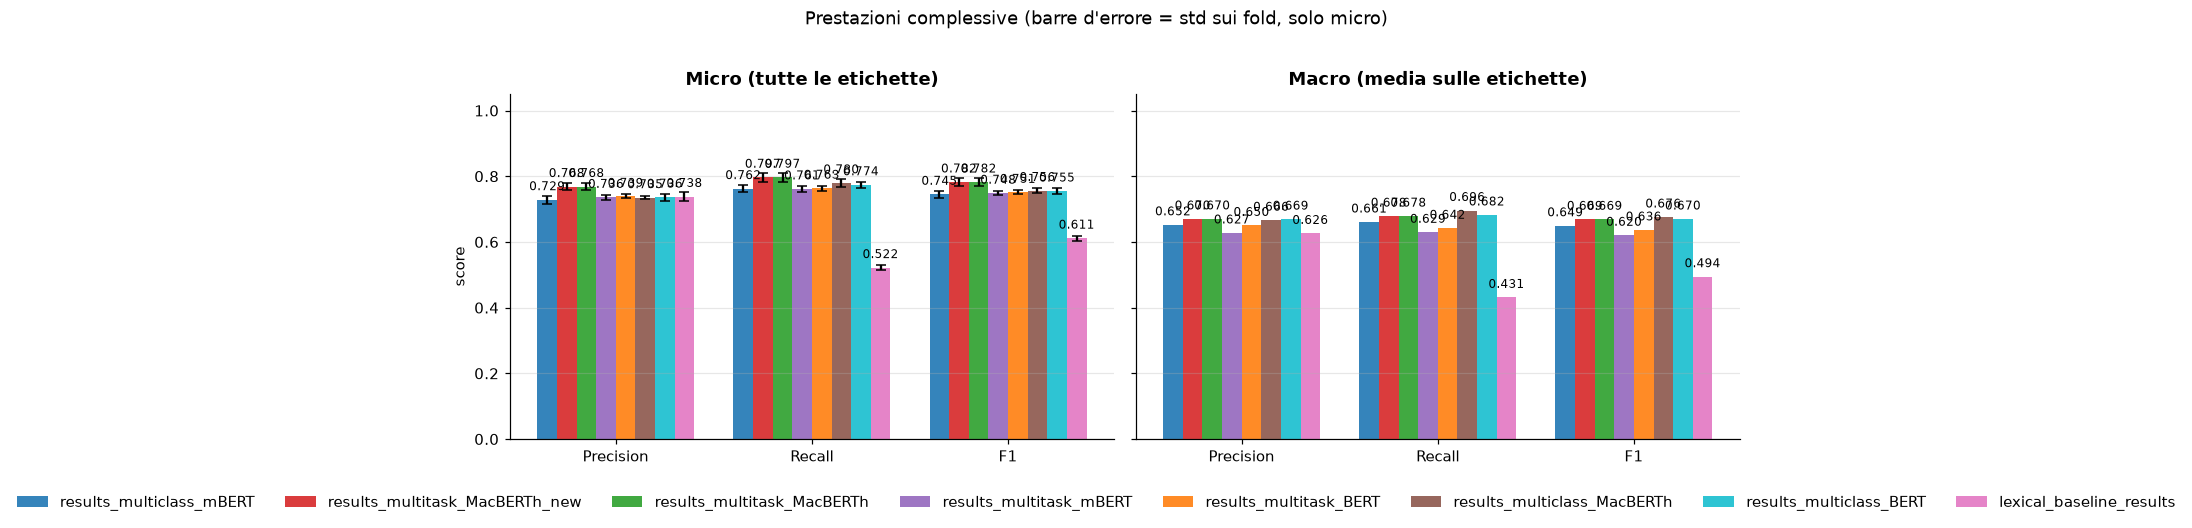

In [139]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
metrics = [("Precision", P, PS), ("Recall", R, RS), ("F1", F, FS)]
x = np.arange(len(metrics))
w = 0.8 / len(MODELS)

for ax, (title, data) in zip(axes, [("Micro (tutte le etichette)", all_micro), ("Macro (media sulle etichette)", macro)]):
    for i, m in enumerate(MODELS):
        row = data[data["model"] == m].iloc[0]
        vals = [row[c] for _, c, _ in metrics]
        has_std = all(s and s in data.columns for _, _, s in metrics)
        errs = [row[s] for _, _, s in metrics] if has_std else None
        pos = x + (i - (len(MODELS) - 1) / 2) * w
        bars = ax.bar(pos, vals, w, yerr=errs, capsize=3, color=COLORS[m], label=m, alpha=0.9)
        for b, v in zip(bars, vals):
            ax.text(b.get_x() + b.get_width() / 2, v + 0.02, f"{v:.3f}", ha="center", va="bottom", fontsize=8)
    ax.set_xticks(x, [t for t, _, _ in metrics])
    ax.set_title(title)
    ax.set_ylim(0, 1.05)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("score")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center",
           ncol=len(MODELS), bbox_to_anchor=(0.5, 0.0), frameon=False)
fig.suptitle("Prestazioni complessive" + (" (barre d'errore = std sui fold, solo micro)" if AGG == "mean" else ""), y=1.02)
fig.tight_layout()
# savefig(fig, "01_overall")
plt.show()

## 4. F1 micro per frame

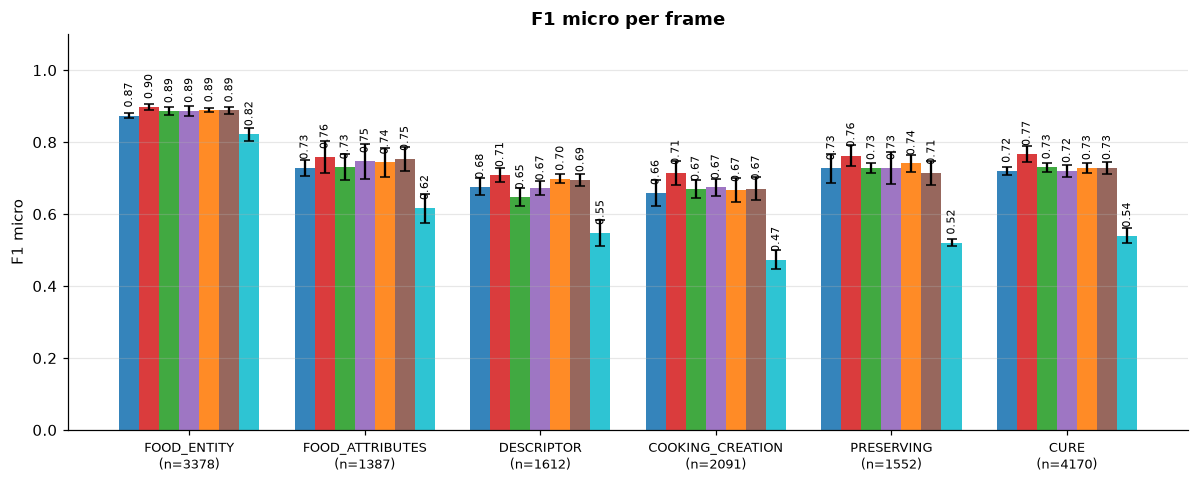

In [128]:
fig, ax = plt.subplots(figsize=(11, 4.5))
x = np.arange(len(FRAME_ORDER))
w = 0.8 / len(MODELS)
for i, m in enumerate(MODELS):
    d = frame_micro[frame_micro["model"] == m].set_index("frame").reindex(FRAME_ORDER)
    pos = x + (i - (len(MODELS) - 1) / 2) * w
    ax.bar(pos, d[F], w, yerr=d[FS] if FS else None, capsize=3, color=COLORS[m], label=m, alpha=0.9)
    for p, v in zip(pos, d[F]):
        ax.text(p, v + 0.03, f"{v:.2f}", ha="center", fontsize=7.5, rotation=90)

support = frame_micro.drop_duplicates("frame").set_index("frame").reindex(FRAME_ORDER)["gold_spans"]
ax.set_xticks(x, [f"{f}\n(n={int(n)})" for f, n in zip(FRAME_ORDER, support)], fontsize=8.5)
ax.set_ylim(0, 1.1)
ax.set_ylabel("F1 micro")
ax.set_title("F1 micro per frame")
# ax.legend(ncol=len(MODELS), loc="lower left")
ax.grid(axis="x", visible=False)
fig.tight_layout()
# savefig(fig, "02_frame_f1")
plt.show()

## 5. F1 per etichetta
Ordinate per frame; tra parentesi il numero di span gold. Le linee grigie separano i frame.

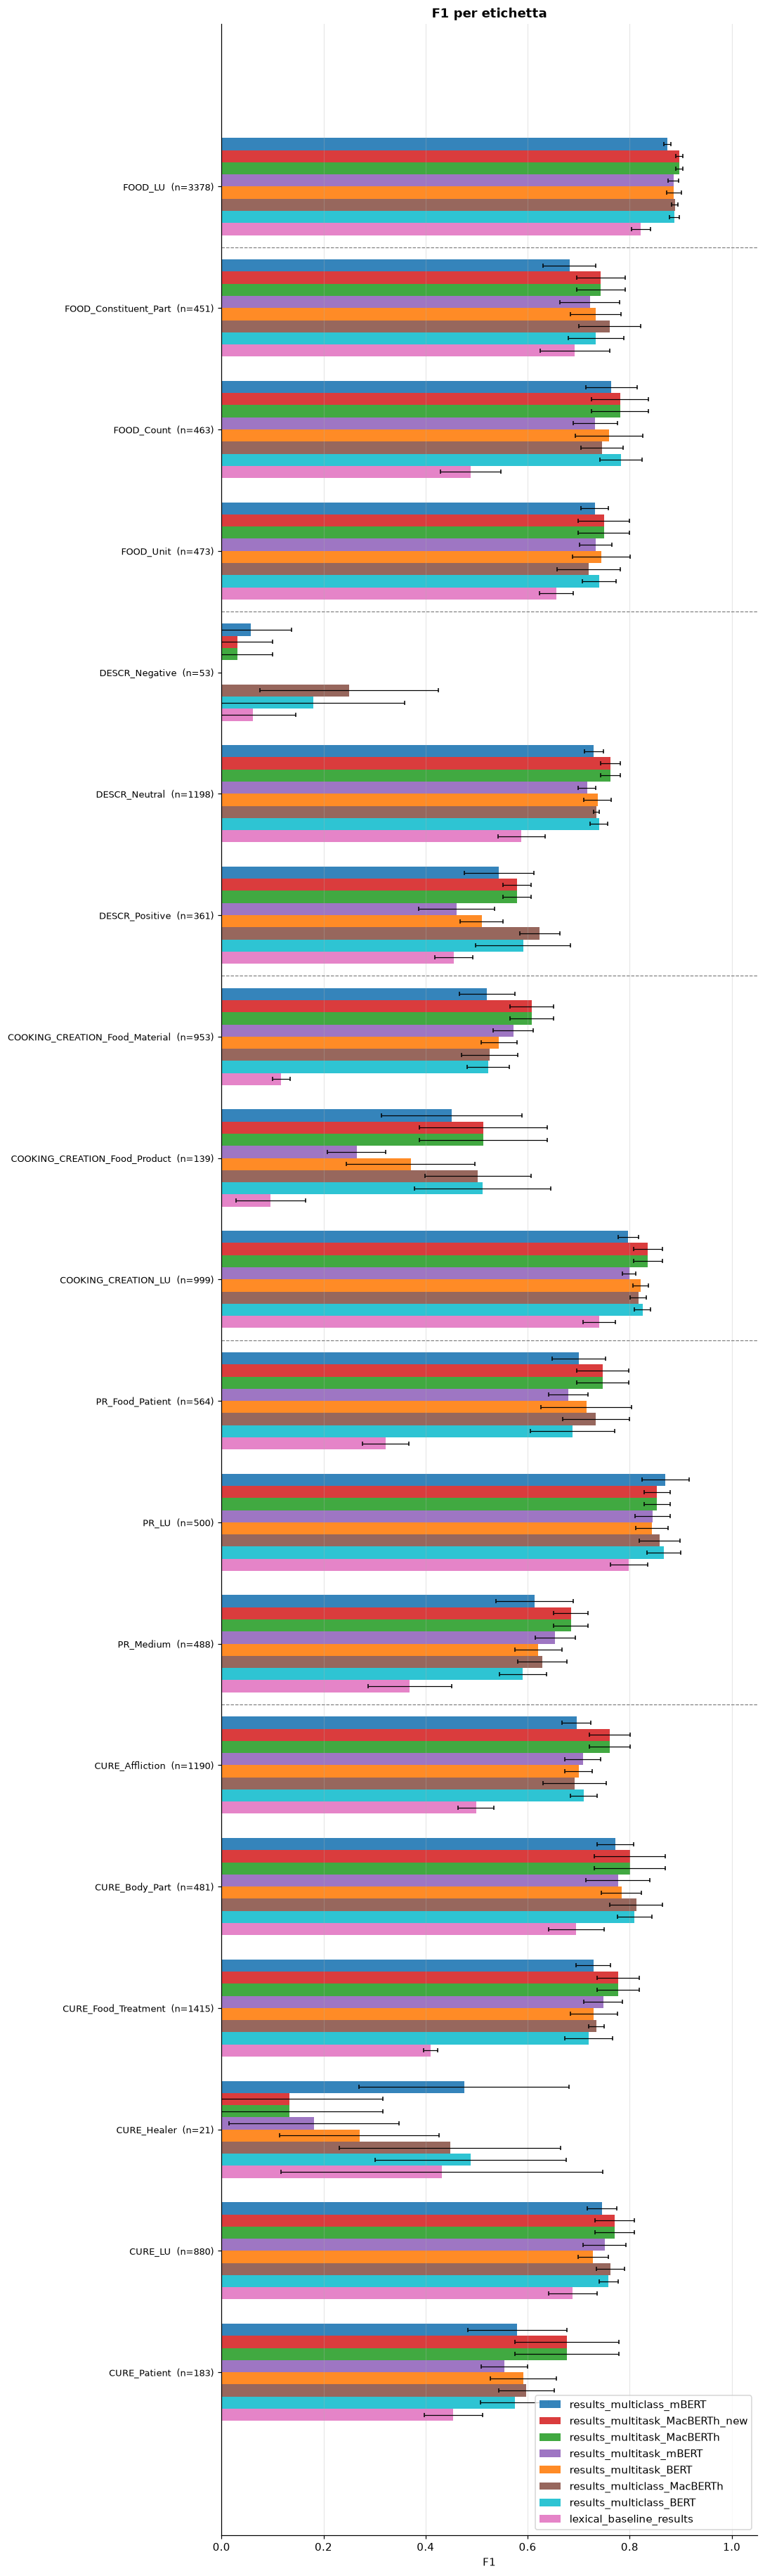

In [140]:
lab = labels_df.drop_duplicates("label").set_index("label").reindex(LABEL_ORDER)
fig, ax = plt.subplots(figsize=(10, 0.42 * len(LABEL_ORDER) * max(1, len(MODELS) / 2) + 1.5))
y = np.arange(len(LABEL_ORDER))
h = 0.8 / len(MODELS)
for i, m in enumerate(MODELS):
    d = labels_df[labels_df["model"] == m].set_index("label").reindex(LABEL_ORDER)
    pos = y + (i - (len(MODELS) - 1) / 2) * h
    ax.barh(pos, d[F], h, xerr=d[FS] if FS else None, capsize=2, color=COLORS[m],
            label=m, alpha=0.9, error_kw={"elinewidth": 0.8})

ax.set_yticks(y, [f"{l}  (n={int(n)})" for l, n in zip(LABEL_ORDER, lab["gold_spans"])], fontsize=8.5)
ax.invert_yaxis()
ax.set_xlim(0, 1.05)
ax.set_xlabel("F1")
ax.set_title("F1 per etichetta")
ax.grid(axis="y", visible=False)

# separatori tra frame
frames_seq = lab["frame"].tolist()
for k in range(1, len(frames_seq)):
    if frames_seq[k] != frames_seq[k - 1]:
        ax.axhline(k - 0.5, color="grey", lw=0.8, ls="--")
ax.legend(loc="lower right")
fig.tight_layout()
# savefig(fig, "03_label_f1")
plt.show()

## 6. Heatmap F1 (etichetta × modello)

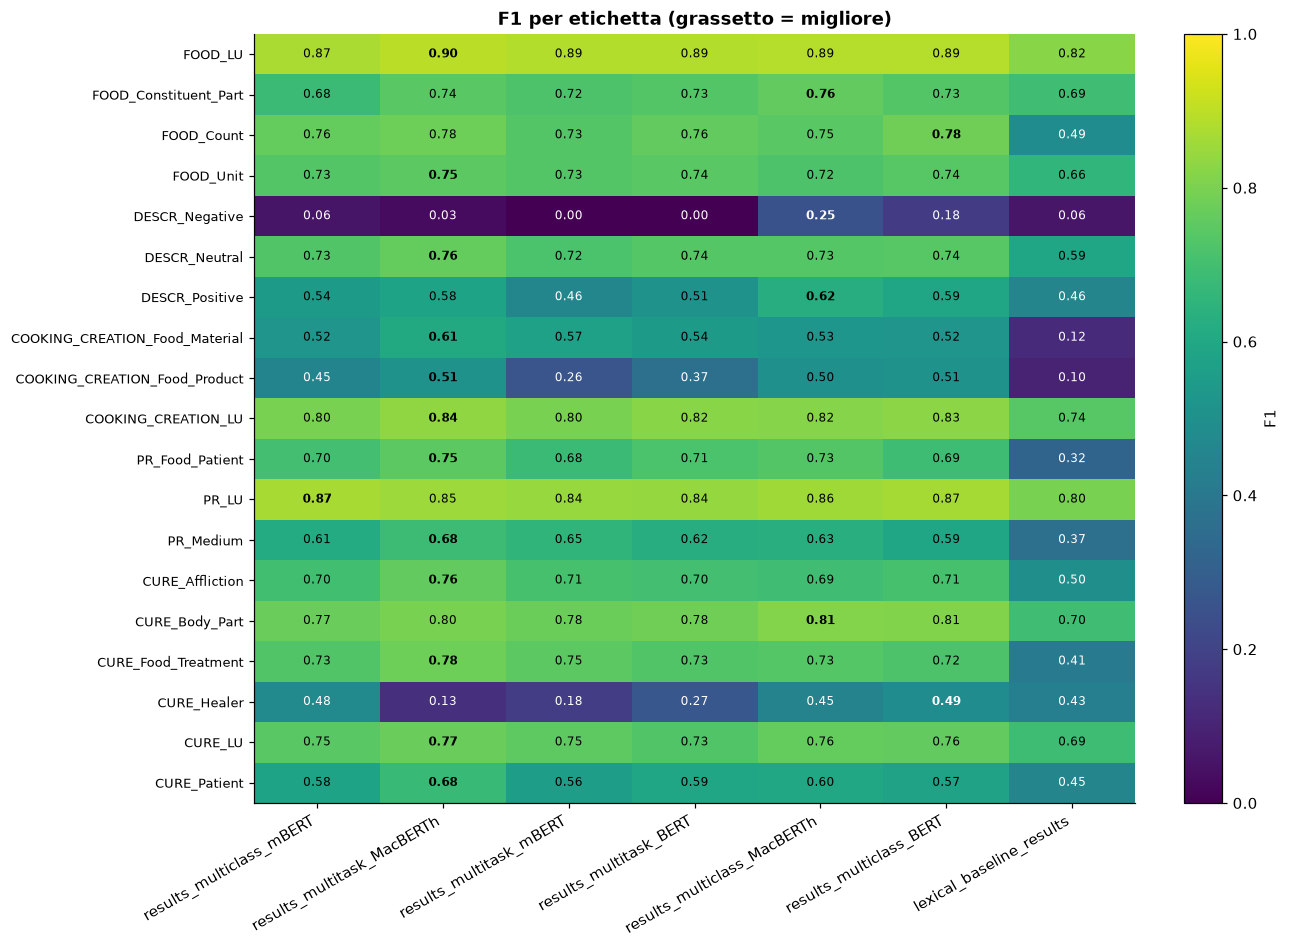

In [146]:
hm = (labels_df.pivot_table(index="label", columns="model", values=F)
      .reindex(index=LABEL_ORDER, columns=MODELS))

fig, ax = plt.subplots(figsize=(2 + 1.4 * len(MODELS), 0.38 * len(LABEL_ORDER) + 1.5))
im = ax.imshow(hm.values, cmap="viridis", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(MODELS)), MODELS, rotation=30, ha="right")
ax.set_yticks(range(len(LABEL_ORDER)), LABEL_ORDER, fontsize=8.5)
ax.grid(False)
best = hm.values.argmax(axis=1)
for r in range(hm.shape[0]):
    for c in range(hm.shape[1]):
        v = hm.values[r, c]
        ax.text(c, r, f"{v:.2f}", ha="center", va="center", fontsize=8,
                color="white" if v < 0.5 else "black",
                fontweight="bold" if c == best[r] else "normal")
fig.colorbar(im, ax=ax, fraction=0.04, label="F1")
ax.set_title("F1 per etichetta (grassetto = migliore)")
fig.tight_layout()
# savefig(fig, "04_heatmap_f1")
plt.show()

## 7. Δ F1 rispetto al modello di riferimento
Barra = F1(modello) − F1(riferimento). Con `AGG="mean"` le barre **piene** indicano che |Δ| supera
la deviazione standard combinata √(std₁² + std₂²) sui fold (euristica di differenza "robusta");
le barre **tratteggiate** sono differenze entro la variabilità tra fold.

In [147]:
print("BASE:", repr(BASE))
print("modelli in labels_df:", labels_df["model"].unique().tolist())
print("MODELS:", MODELS)
print("etichette mancanti in labels_df:",
      sorted(set(LABEL_ORDER) - set(labels_df["label"])))
print("NaN in base[F]:",
      labels_df[labels_df["model"] == BASE].set_index("label").reindex(LABEL_ORDER)[F].isna().sum(),
      "su", len(LABEL_ORDER))

BASE: 'lexical_baseline_results.tsv'
modelli in labels_df: ['results_multiclass_mBERT', 'results_multitask_MacBERTh', 'results_multitask_mBERT', 'results_multitask_BERT', 'results_multiclass_MacBERTh', 'results_multiclass_BERT', 'lexical_baseline_results']
MODELS: ['results_multiclass_mBERT', 'results_multitask_MacBERTh', 'results_multitask_mBERT', 'results_multitask_BERT', 'results_multiclass_MacBERTh', 'results_multiclass_BERT', 'lexical_baseline_results']
etichette mancanti in labels_df: []
NaN in base[F]: 19 su 19


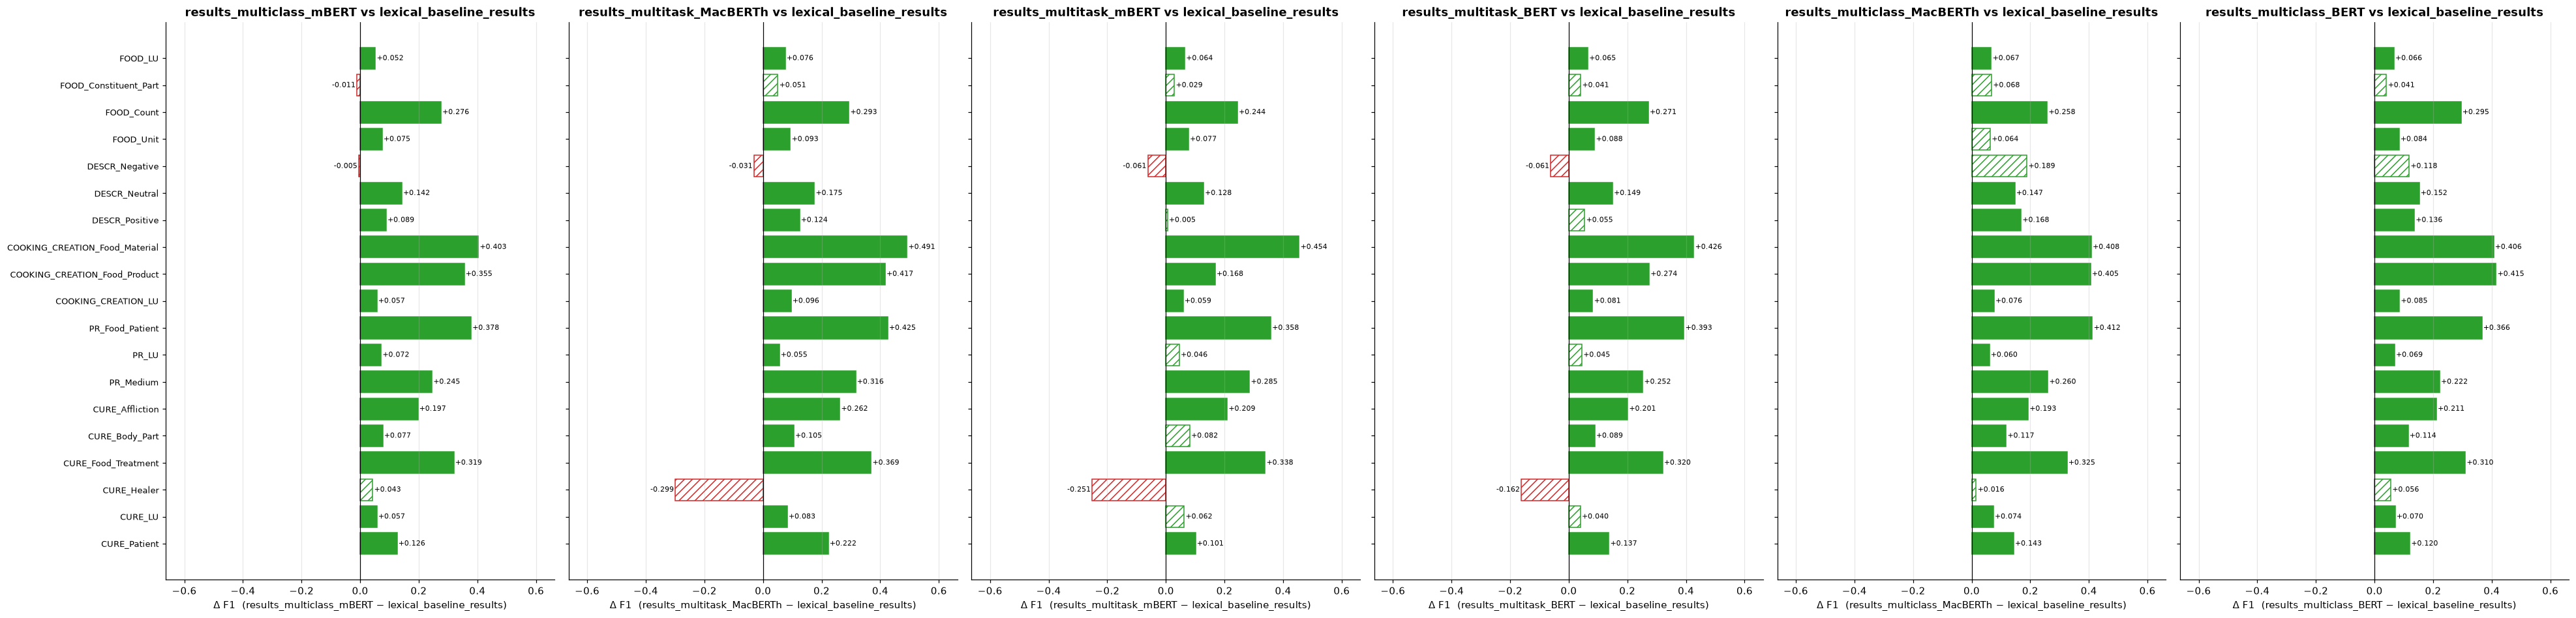

In [148]:
BASE = "lexical_baseline_results"

others = [m for m in MODELS if m != BASE]
if not others:
    print("Serve almeno un secondo modello per il confronto Δ.")
else:
    base = labels_df[labels_df["model"] == BASE].set_index("label").reindex(LABEL_ORDER)
    fig, axes = plt.subplots(1, len(others), figsize=(max(8, 6 * len(others)), 0.38 * len(LABEL_ORDER) + 1.5),
                             sharey=True, squeeze=False)
    lim = 0.05
    for m in others:
        d = labels_df[labels_df["model"] == m].set_index("label").reindex(LABEL_ORDER)
        lim = max(lim, (d[F] - base[F]).abs().max() * 1.35)
    for ax, m in zip(axes[0], others):
        d = labels_df[labels_df["model"] == m].set_index("label").reindex(LABEL_ORDER)
        delta = d[F] - base[F]
        robust = (delta.abs() > np.sqrt(d[FS]**2 + base[FS]**2)) if FS else pd.Series(True, index=delta.index)
        y = np.arange(len(LABEL_ORDER))
        for yi, (dv, rb) in enumerate(zip(delta, robust)):
            col = "#2ca02c" if dv >= 0 else "#d62728"
            ax.barh(yi, dv, color=col if rb else "none", edgecolor=col,
                    hatch=None if rb else "///", lw=1)
            ax.text(dv + (0.005 if dv >= 0 else -0.005), yi, f"{dv:+.3f}",
                    va="center", ha="left" if dv >= 0 else "right", fontsize=7.5)
        ax.axvline(0, color="black", lw=0.8)
        ax.set_yticks(y, LABEL_ORDER, fontsize=8.5)
        ax.set_xlim(-lim, lim)
        ax.set_xlabel(f"Δ F1  ({m} − {BASE})")
        ax.set_title(f"{m} vs {BASE}")
        ax.grid(axis="y", visible=False)
    axes[0][0].invert_yaxis()   # una sola volta: gli assi y sono condivisi
    fig.tight_layout()
    # savefig(fig, "05_delta_f1")
    plt.show()

## 8. Precision vs Recall per etichetta
Ogni etichetta è un segmento che collega i modelli: si vede subito se un modello guadagna in precisione, in recall o in entrambi. Curve grigie = iso-F1.

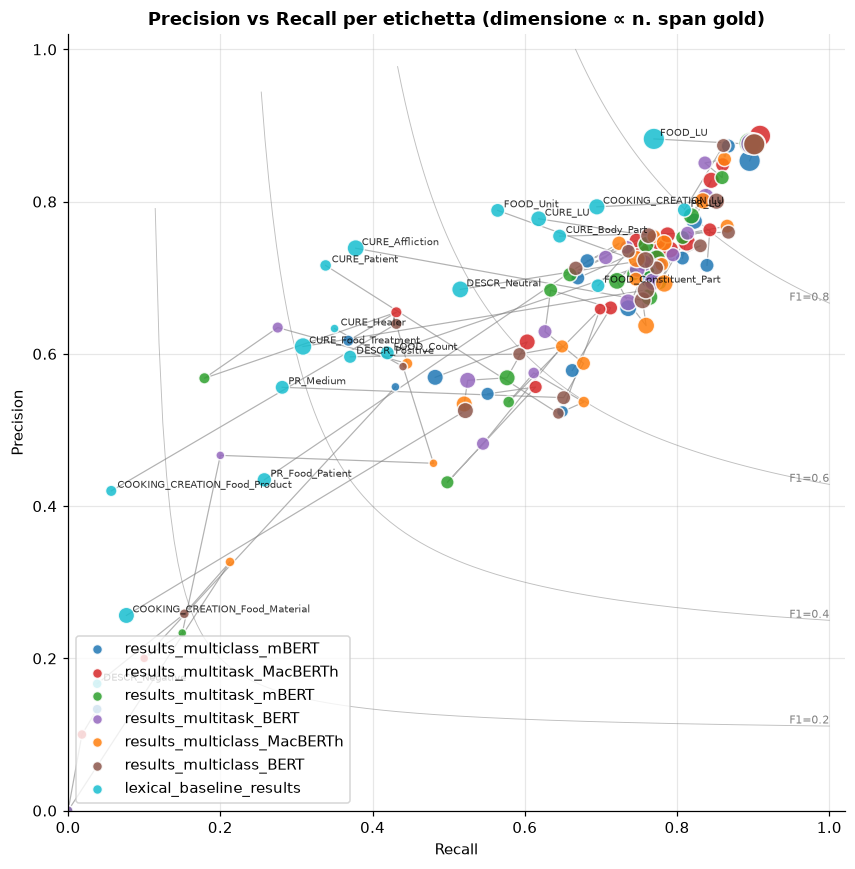

In [149]:
fig, ax = plt.subplots(figsize=(8.5, 8))

# curve iso-F1
rr = np.linspace(0.01, 1, 200)
for f1 in [0.2, 0.4, 0.6, 0.8]:
    pp = f1 * rr / (2 * rr - f1)
    ok = (pp > 0) & (pp <= 1)
    ax.plot(rr[ok], pp[ok], color="grey", lw=0.6, alpha=0.5)
    ax.text(1.0, f1 / (2 - f1), f"F1={f1}", fontsize=7, color="grey", va="bottom", ha="right")

piv = labels_df.pivot_table(index="label", columns="model", values=[P, R]).reindex(LABEL_ORDER)
for lbl in LABEL_ORDER:
    xs = [piv.loc[lbl, (R, m)] for m in MODELS]
    ys = [piv.loc[lbl, (P, m)] for m in MODELS]
    ax.plot(xs, ys, color="grey", lw=0.8, alpha=0.6, zorder=1)
    ax.annotate(lbl, (xs[-1], ys[-1]), fontsize=6.5, xytext=(4, 2), textcoords="offset points", alpha=0.8)

sizes = labels_df.drop_duplicates("label").set_index("label")["gold_spans"]
for m in MODELS:
    d = labels_df[labels_df["model"] == m]
    ax.scatter(d[R], d[P], s=20 + 180 * np.sqrt(d["gold_spans"] / sizes.max()),
               color=COLORS[m], label=m, alpha=0.85, edgecolor="white", zorder=2)

ax.set_xlim(0, 1.02); ax.set_ylim(0, 1.02)
ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
ax.set_title("Precision vs Recall per etichetta (dimensione ∝ n. span gold)")
leg = ax.legend(loc="lower left", markerscale=0.6)
ax.set_aspect("equal")
fig.tight_layout()
# savefig(fig, "06_pr_scatter")
plt.show()

## 9. F1 vs numero di esempi gold
Utile per vedere se le differenze tra modelli si concentrano sulle classi rare.

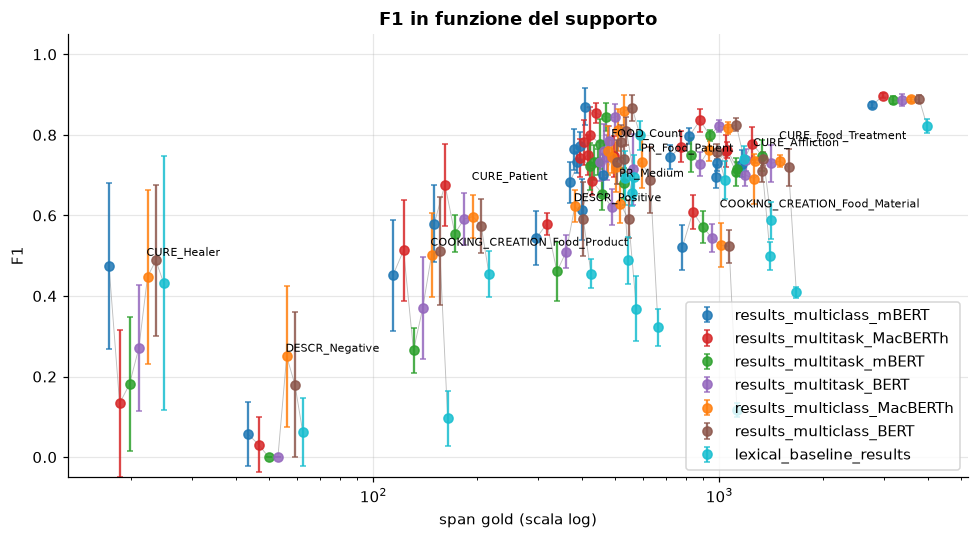

In [150]:
fig, ax = plt.subplots(figsize=(9, 5))
jit = {m: 1 + 0.06 * (i - (len(MODELS) - 1) / 2) for i, m in enumerate(MODELS)}  # jitter orizzontale
for m in MODELS:
    d = labels_df[labels_df["model"] == m]
    ax.errorbar(d["gold_spans"] * jit[m], d[F], yerr=d[FS] if FS else None, fmt="o",
                color=COLORS[m], label=m, alpha=0.85, capsize=2, ms=6)
# collega lo stesso label tra modelli
for lbl, g in labels_df.groupby("label"):
    ax.plot(g["gold_spans"] * g["model"].map(jit), g[F], color="grey", lw=0.6, alpha=0.5, zorder=0)
    if g["gold_spans"].iloc[0] < 200 or g[F].min() < 0.55:
        ax.annotate(lbl, (g["gold_spans"].iloc[0], g[F].max()), fontsize=7,
                    xytext=(5, 3), textcoords="offset points")
ax.set_xscale("log")
ax.set_xlabel("span gold (scala log)")
ax.set_ylabel("F1")
ax.set_ylim(-0.05, 1.05)
ax.set_title("F1 in funzione del supporto")
ax.legend(loc="lower right")
fig.tight_layout()
# savefig(fig, "07_f1_vs_support")
plt.show()

## 10. Composizione degli errori (TP / FP / FN)
Valori pooled sui 5 fold, normalizzati sul numero di span gold di ciascuna etichetta (FN + TP = 100%).

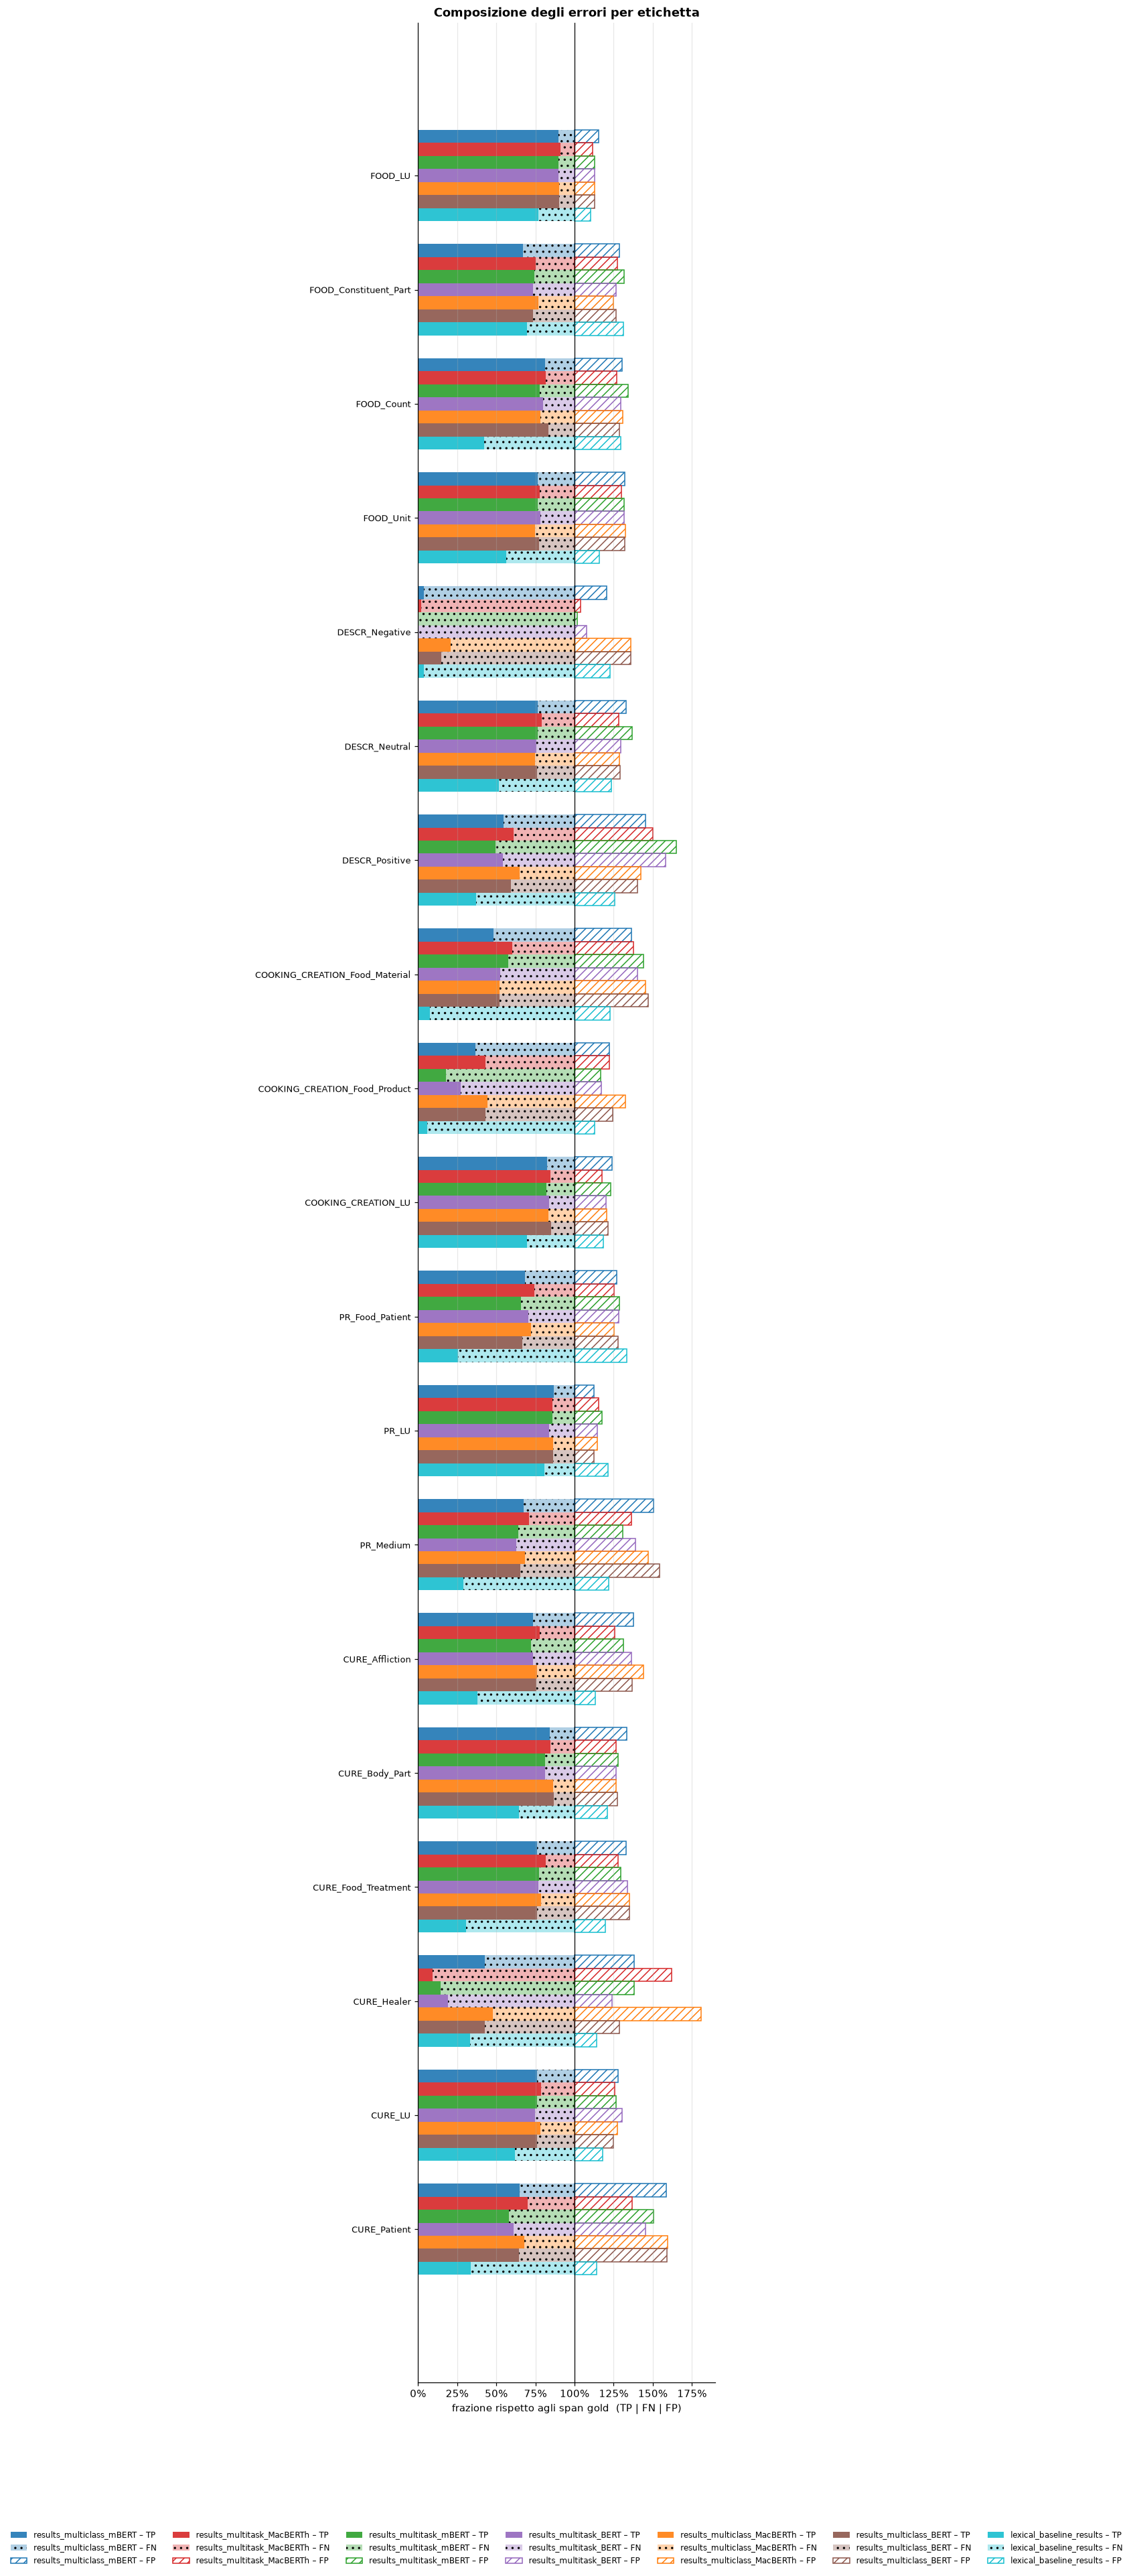

In [151]:
fig, ax = plt.subplots(figsize=(11, 0.5 * len(LABEL_ORDER) * max(1, len(MODELS) / 2) + 1.5))
y = np.arange(len(LABEL_ORDER))
h = 0.8 / len(MODELS)
for i, m in enumerate(MODELS):
    d = labels_df[labels_df["model"] == m].set_index("label").reindex(LABEL_ORDER)
    g = d["gold_spans"]
    tp, fn, fp = d["tp"] / g, d["fn"] / g, d["fp"] / g
    pos = y + (i - (len(MODELS) - 1) / 2) * h
    ax.barh(pos, tp, h, color=COLORS[m], alpha=0.9, label=f"{m} – TP")
    ax.barh(pos, fn, h, left=tp, color=COLORS[m], alpha=0.35, hatch="..", label=f"{m} – FN")
    ax.barh(pos, fp, h, left=tp + fn, color="none", edgecolor=COLORS[m], hatch="///", label=f"{m} – FP")
ax.axvline(1, color="black", lw=0.8)
ax.set_yticks(y, LABEL_ORDER, fontsize=8.5)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("frazione rispetto agli span gold  (TP | FN | FP)")
ax.set_title("Composizione degli errori per etichetta")
ax.grid(axis="y", visible=False)
ax.legend(ncol=len(MODELS), fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.06), frameon=False)
fig.tight_layout()
# savefig(fig, "08_error_composition")
plt.show()

## 11. Radar per frame (F1 micro)

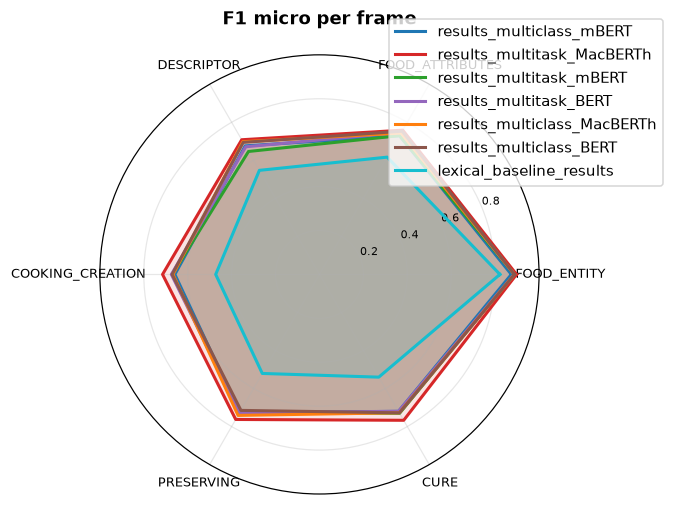

In [152]:
cats = FRAME_ORDER
ang = np.linspace(0, 2 * np.pi, len(cats), endpoint=False).tolist()
ang += ang[:1]

fig, ax = plt.subplots(figsize=(6.5, 6.5), subplot_kw={"polar": True})
for m in MODELS:
    d = frame_micro[frame_micro["model"] == m].set_index("frame").reindex(cats)[F].tolist()
    d += d[:1]
    ax.plot(ang, d, color=COLORS[m], lw=2, label=m)
    ax.fill(ang, d, color=COLORS[m], alpha=0.12)
ax.set_xticks(ang[:-1], cats, fontsize=8.5)
ax.set_ylim(0, 1)
ax.set_yticks([0.2, 0.4, 0.6, 0.8], ["0.2", "0.4", "0.6", "0.8"], fontsize=7)
ax.set_title("F1 micro per frame", pad=20)
ax.legend(loc="upper right", bbox_to_anchor=(1.3, 1.1))
fig.tight_layout()
# savefig(fig, "09_radar_frames")
plt.show()

## 12. Classifica: chi vince su quante etichette

In [153]:
if len(MODELS) > 1:
    winners = hm.idxmax(axis=1)
    counts = winners.value_counts().reindex(MODELS, fill_value=0)
    print("Etichette in cui ciascun modello ha l'F1 più alto:")
    print(counts.to_string())
    print()
    if len(MODELS) == 2 and FS:
        a, b = MODELS
        da = labels_df[labels_df["model"] == a].set_index("label").reindex(LABEL_ORDER)
        db = labels_df[labels_df["model"] == b].set_index("label").reindex(LABEL_ORDER)
        delta = db[F] - da[F]
        robust = delta.abs() > np.sqrt(da[FS]**2 + db[FS]**2)
        print(f"Differenze oltre la std combinata ({b} − {a}):")
        print(delta[robust].round(3).sort_values().to_string() if robust.any() else "  nessuna")

Etichette in cui ciascun modello ha l'F1 più alto:
results_multiclass_mBERT        1
results_multitask_MacBERTh     12
results_multitask_mBERT         0
results_multitask_BERT          0
results_multiclass_MacBERTh     4
results_multiclass_BERT         2
lexical_baseline_results        0



## Note
- **mean vs pooled**: `*_mean` è la media delle metriche calcolate su ogni fold (con std), `*_pooled` somma TP/FP/FN di tutti i fold prima di calcolare le metriche. Cambia `AGG` in cima per passare dall'una all'altra.
- La riga `<ALL>/<macro>` dei file è vuota, quindi la macro-media viene ricalcolata qui come media non pesata delle etichette.
- Il criterio "|Δ| > √(std₁² + std₂²)" è solo un'euristica visiva. Per un test vero servirebbero le predizioni per fold/istanza (es. paired t-test sui fold o bootstrap).
- Etichette con pochissimi esempi (es. `CURE_Healer`, n=21; `DESCR_Negative`, n=53) hanno std molto alte: le differenze lì vanno lette con cautela.